# 📈 Evolução Temporal - Time Series

Análise da evolução dos votos ao longo do tempo com base nos snapshots coletados.

**O que você verá:**
- Linha do tempo de apuração
- Evolução de votos por candidato
- Crescimento de seções apuradas
- Margem entre líderes ao longo do tempo
- Estabilização dos resultados

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json
✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Construindo DataFrame Temporal

In [2]:

# Build time series dataframe
records = []
for snap in all_snapshots:
    ts = pd.to_datetime(snap['scraped_at_utc'])
    for cand in snap['candidatos']:
        records.append({
            'timestamp': ts,
            'file': snap['file'],
            'secoes_apuradas': snap['secoes_apuradas'],
            'pct_apuradas': snap['pct_apuradas'],
            'candidato': cand['nome_urna'],
            'partido': cand['partido'],
            'votos': cand['votos'],
            'percentual': cand['percentual']
        })

df_ts = pd.DataFrame(records)
print(f"Total registros: {len(df_ts)} (snapshots x candidatos)")
print(f"Período: {df_ts['timestamp'].min()} a {df_ts['timestamp'].max()}")
df_ts.head()


Total registros: 516 (snapshots x candidatos)
Período: 2026-10-05 00:02:11+00:00 a 2026-10-14 19:22:15+00:00


,timestamp,file,secoes_apuradas,pct_apuradas,candidato,partido,votos,percentual
0,2026-10-05 00:02:11+00:00,presidente_br_20261005_000211Z.json,474312,95.01,FLAVIO BOLSONARO,PL,53867670,47.63
1,2026-10-05 00:02:11+00:00,presidente_br_20261005_000211Z.json,474312,95.01,LULA,PT,50267135,44.45
2,2026-10-05 00:02:11+00:00,presidente_br_20261005_000211Z.json,474312,95.01,ESCRITOR AUGUSTO CURY,AVANTE,3299202,2.92
3,2026-10-05 00:02:11+00:00,presidente_br_20261005_000211Z.json,474312,95.01,RENAN SANTOS,MISSÃO,2575936,2.28
4,2026-10-05 00:02:11+00:00,presidente_br_20261005_000211Z.json,474312,95.01,RONALDO CAIADO,PSD,2514883,2.22


In [3]:

# Pivot for easier plotting: one column per candidate
df_pivot_votos = df_ts.pivot_table(index='timestamp', columns='candidato', values='votos', aggfunc='first')
df_pivot_pct = df_ts.pivot_table(index='timestamp', columns='candidato', values='percentual', aggfunc='first')
df_pivot_votos.tail()


candidato,CLARIANA BARAO,EDMILSON COSTA,ESCRITOR AUGUSTO CURY,FLAVIO BOLSONARO,HERTZ DIAS,LULA,RENAN SANTOS,RONALDO CAIADO,RUI COSTA PIMENTA,SAMARA,VETERINÁRIO WILSON GRASSI,ZEMA
timestamp,,,,,,,,,,,,
2026-10-14 00:44:57+00:00,40043,22693,3448569,56104503,43103,53879538,2675887,2605148,15024,122911,16881,326488
2026-10-14 05:25:27+00:00,40043,22693,3448569,56104503,43103,53879538,2675887,2605148,15024,122911,16881,326488
2026-10-14 10:22:09+00:00,40043,22693,3448569,56104503,43103,53879538,2675887,2605148,15024,122911,16881,326488
2026-10-14 15:14:09+00:00,40043,22693,3448569,56104503,43103,53879538,2675887,2605148,15024,122911,16881,326488
2026-10-14 19:22:15+00:00,40043,22693,3448569,56104503,43103,53879538,2675887,2605148,15024,122911,16881,326488


## 2. Evolução de Seções Apuradas

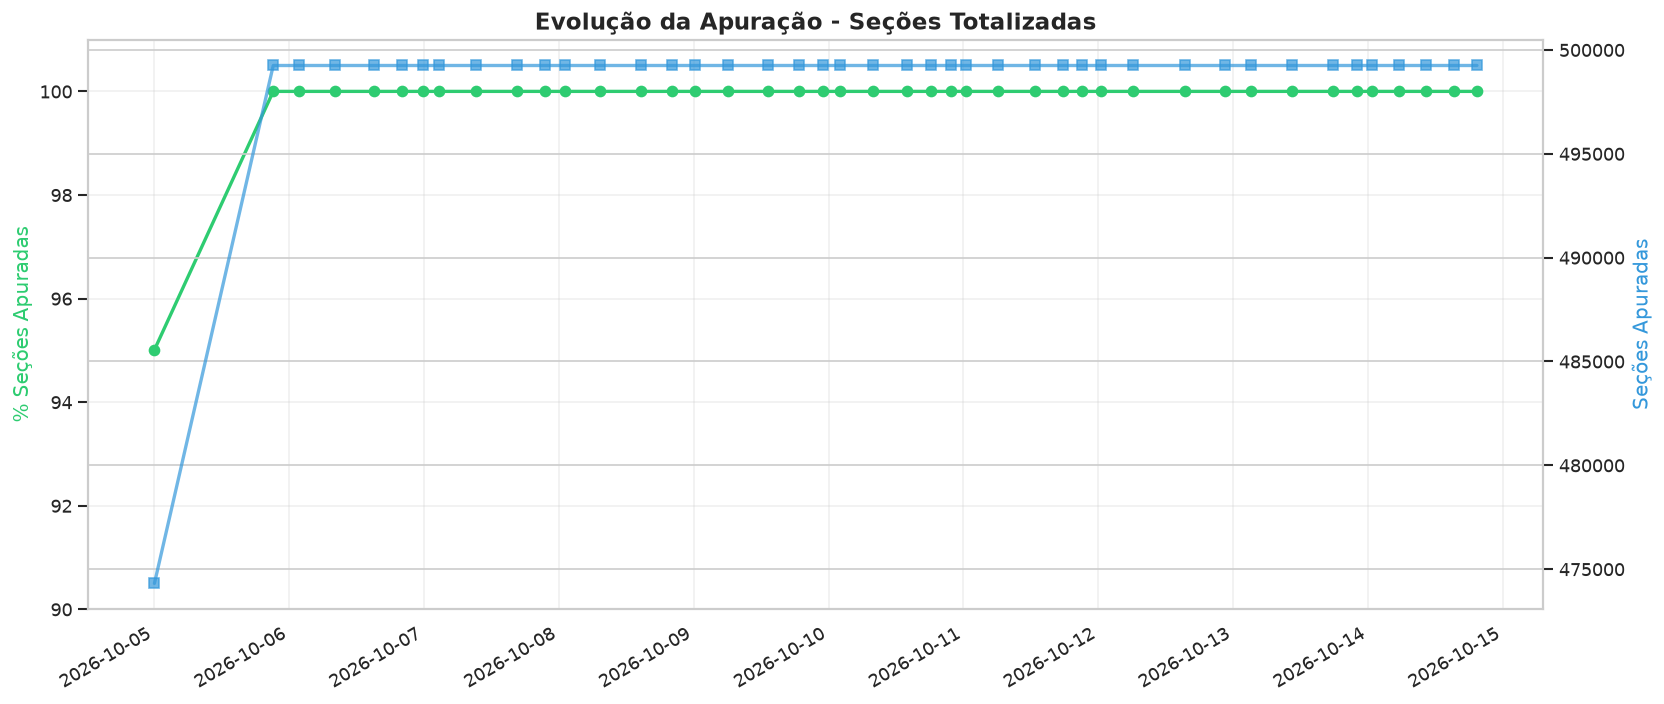

,timestamp,secoes_apuradas,pct_apuradas,votos_validos
33,2026-10-12 22:31:18+00:00,499248,100.0,119300788
34,2026-10-13 03:07:23+00:00,499248,100.0,119300788
35,2026-10-13 10:26:02+00:00,499248,100.0,119300788
36,2026-10-13 17:41:09+00:00,499248,100.0,119300788
37,2026-10-13 21:56:46+00:00,499248,100.0,119300788
38,2026-10-14 00:44:57+00:00,499248,100.0,119300788
39,2026-10-14 05:25:27+00:00,499248,100.0,119300788
40,2026-10-14 10:22:09+00:00,499248,100.0,119300788
41,2026-10-14 15:14:09+00:00,499248,100.0,119300788
42,2026-10-14 19:22:15+00:00,499248,100.0,119300788


In [4]:

df_sections = pd.DataFrame([{
    'timestamp': pd.to_datetime(s['scraped_at_utc']),
    'secoes_apuradas': s['secoes_apuradas'],
    'pct_apuradas': s['pct_apuradas'],
    'votos_validos': s['votos_validos']
} for s in all_snapshots]).sort_values('timestamp')

plt.figure(figsize=(14, 6))
ax1 = plt.gca()
ax1.plot(df_sections['timestamp'], df_sections['pct_apuradas'], marker='o', linewidth=2, color='#2ecc71', label='% Apuradas')
ax1.set_ylabel('% Seções Apuradas', color='#2ecc71')
ax1.set_ylim(90, 101)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(df_sections['timestamp'], df_sections['secoes_apuradas'], marker='s', linewidth=2, color='#3498db', alpha=0.7, label='Qtd Seções')
ax2.set_ylabel('Seções Apuradas', color='#3498db')

plt.title('Evolução da Apuração - Seções Totalizadas', fontweight='bold')
fig = plt.gcf()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('timeseries_sections.png', dpi=150, bbox_inches='tight')
plt.show()

df_sections.tail(10)


## 3. Evolução de Votos - Todos Candidatos (Milhões)

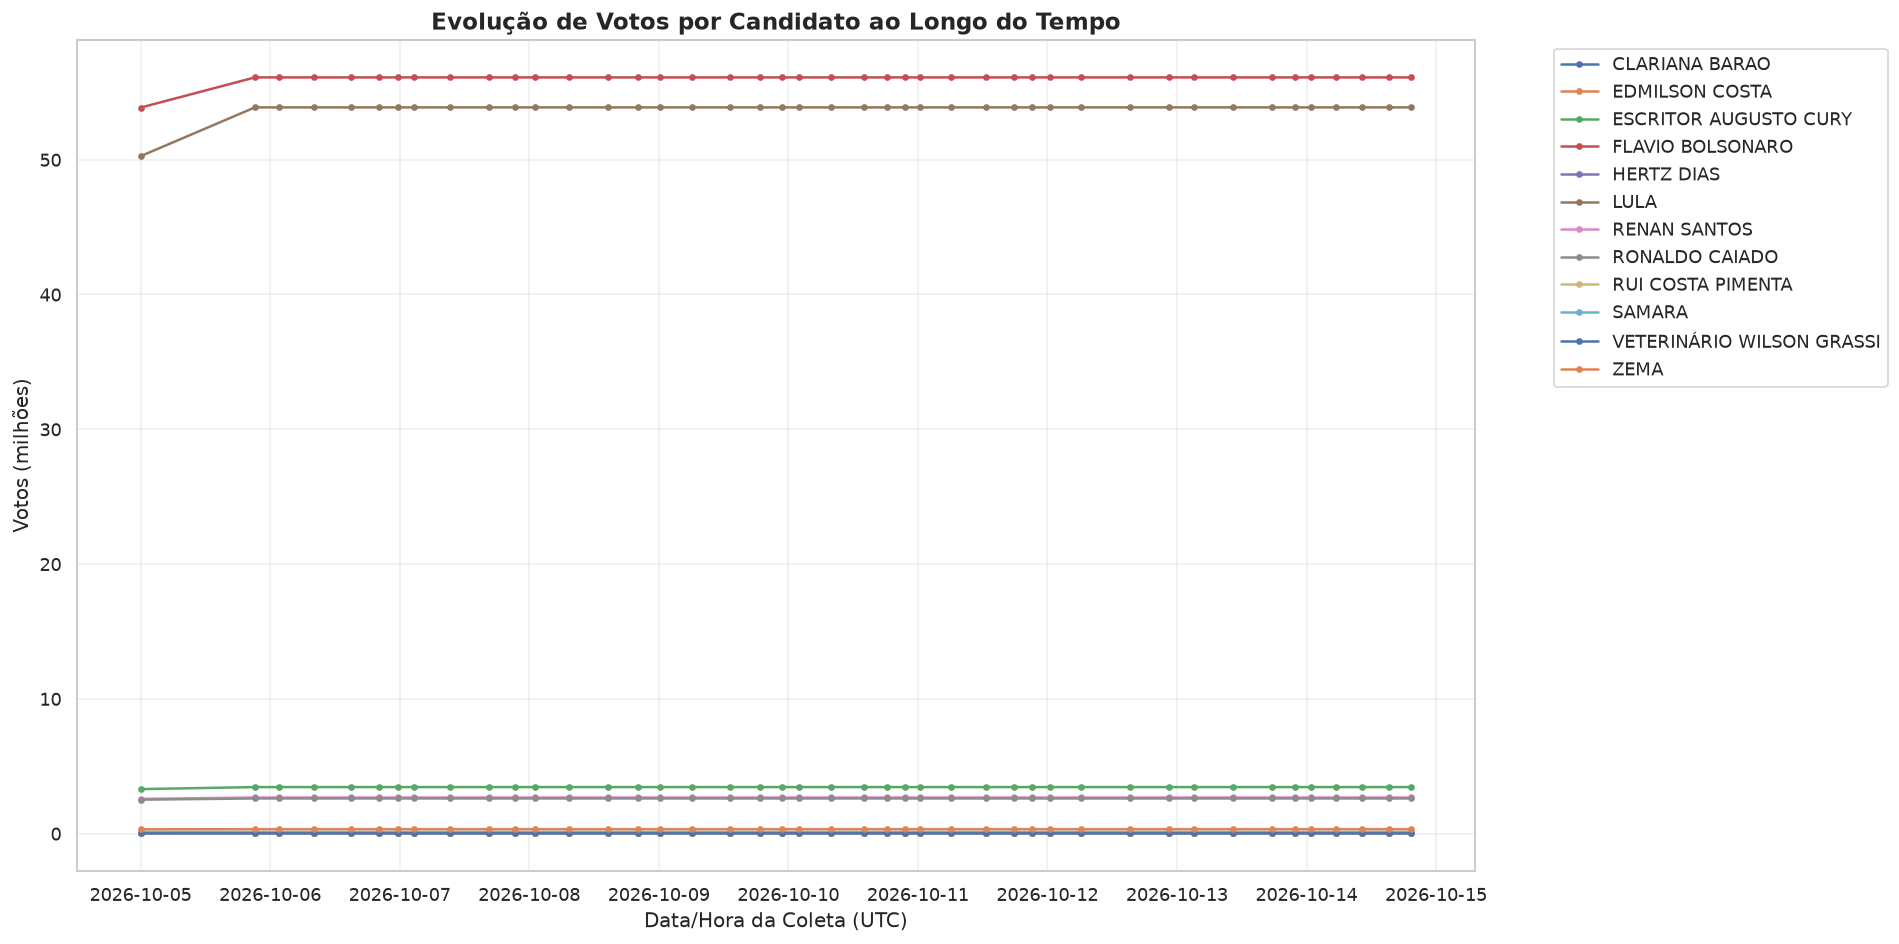

In [5]:

plt.figure(figsize=(16, 8))
for col in df_pivot_votos.columns:
    plt.plot(df_pivot_votos.index, df_pivot_votos[col]/1e6, marker='o', markersize=3, linewidth=1.5, label=col)

plt.xlabel('Data/Hora da Coleta (UTC)')
plt.ylabel('Votos (milhões)')
plt.title('Evolução de Votos por Candidato ao Longo do Tempo', fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('timeseries_all_candidates.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Evolução Percentual - Top 4 Candidatos

Top 4: ['FLAVIO BOLSONARO', 'LULA', 'ESCRITOR AUGUSTO CURY', 'RENAN SANTOS']


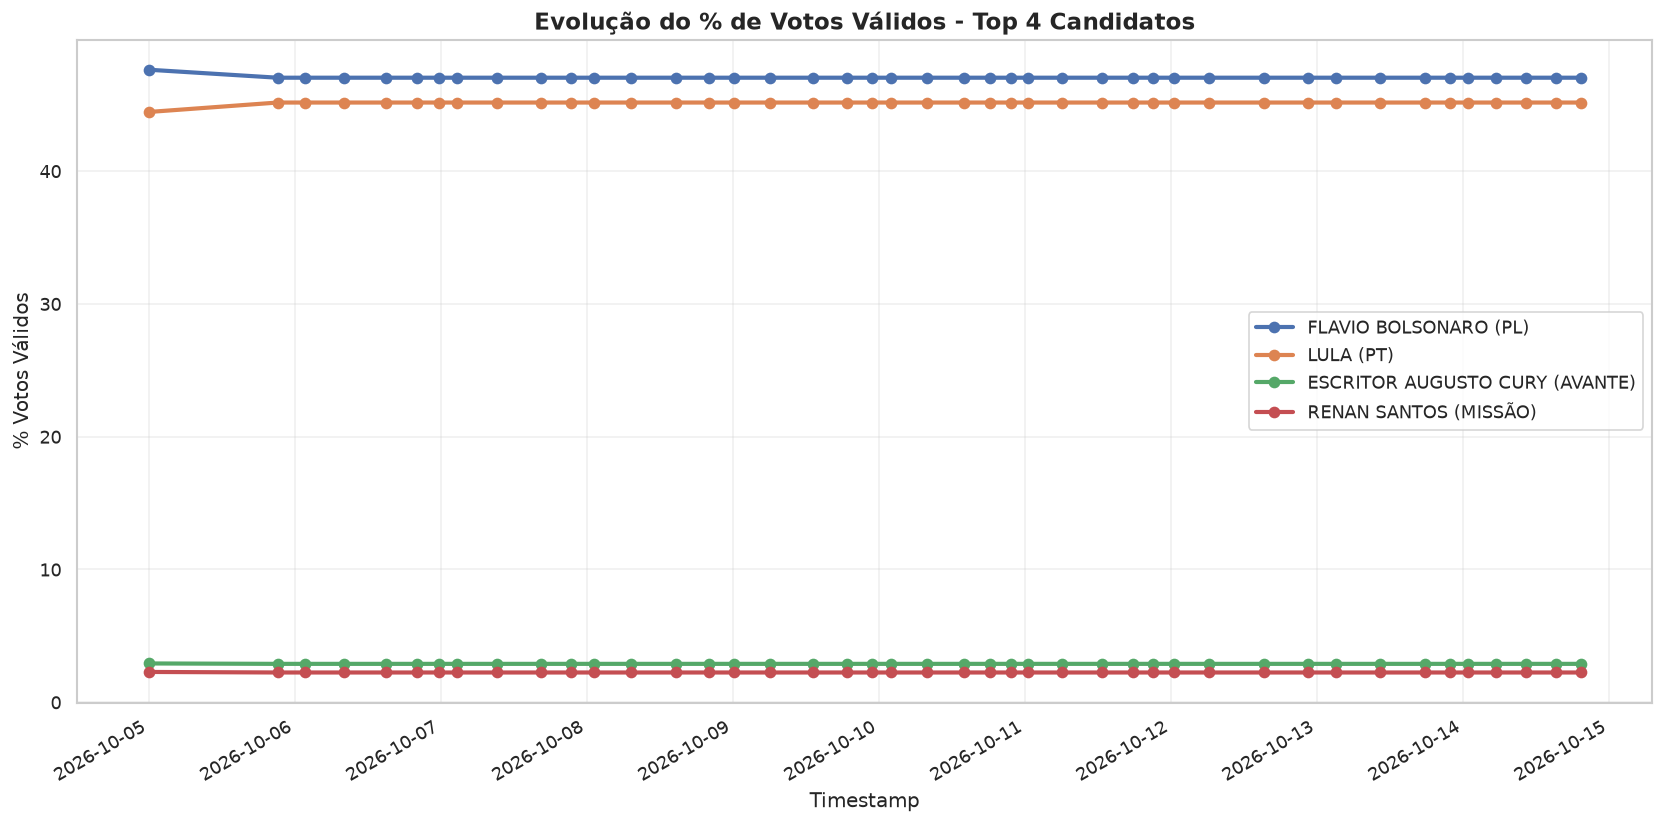

In [6]:

top_candidates = df_ts.groupby('candidato')['votos'].max().sort_values(ascending=False).head(4).index.tolist()
print(f"Top 4: {top_candidates}")

plt.figure(figsize=(14, 7))
for cand in top_candidates:
    data = df_ts[df_ts['candidato']==cand].sort_values('timestamp')
    plt.plot(data['timestamp'], data['percentual'], marker='o', linewidth=2.5, label=f"{cand} ({data['partido'].iloc[0]})")

plt.xlabel('Timestamp')
plt.ylabel('% Votos Válidos')
plt.title('Evolução do % de Votos Válidos - Top 4 Candidatos', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
fig = plt.gcf()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('timeseries_top4_pct.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Margem entre Líderes

                   timestamp             lider segundo  votos_lider  \
38 2026-10-14 00:44:57+00:00  FLAVIO BOLSONARO    LULA     56104503   
39 2026-10-14 05:25:27+00:00  FLAVIO BOLSONARO    LULA     56104503   
40 2026-10-14 10:22:09+00:00  FLAVIO BOLSONARO    LULA     56104503   
41 2026-10-14 15:14:09+00:00  FLAVIO BOLSONARO    LULA     56104503   
42 2026-10-14 19:22:15+00:00  FLAVIO BOLSONARO    LULA     56104503   

    votos_segundo  diferenca_votos  diferenca_pct  pct_apuradas  
38       53879538          2224965           1.87         100.0  
39       53879538          2224965           1.87         100.0  
40       53879538          2224965           1.87         100.0  
41       53879538          2224965           1.87         100.0  
42       53879538          2224965           1.87         100.0  


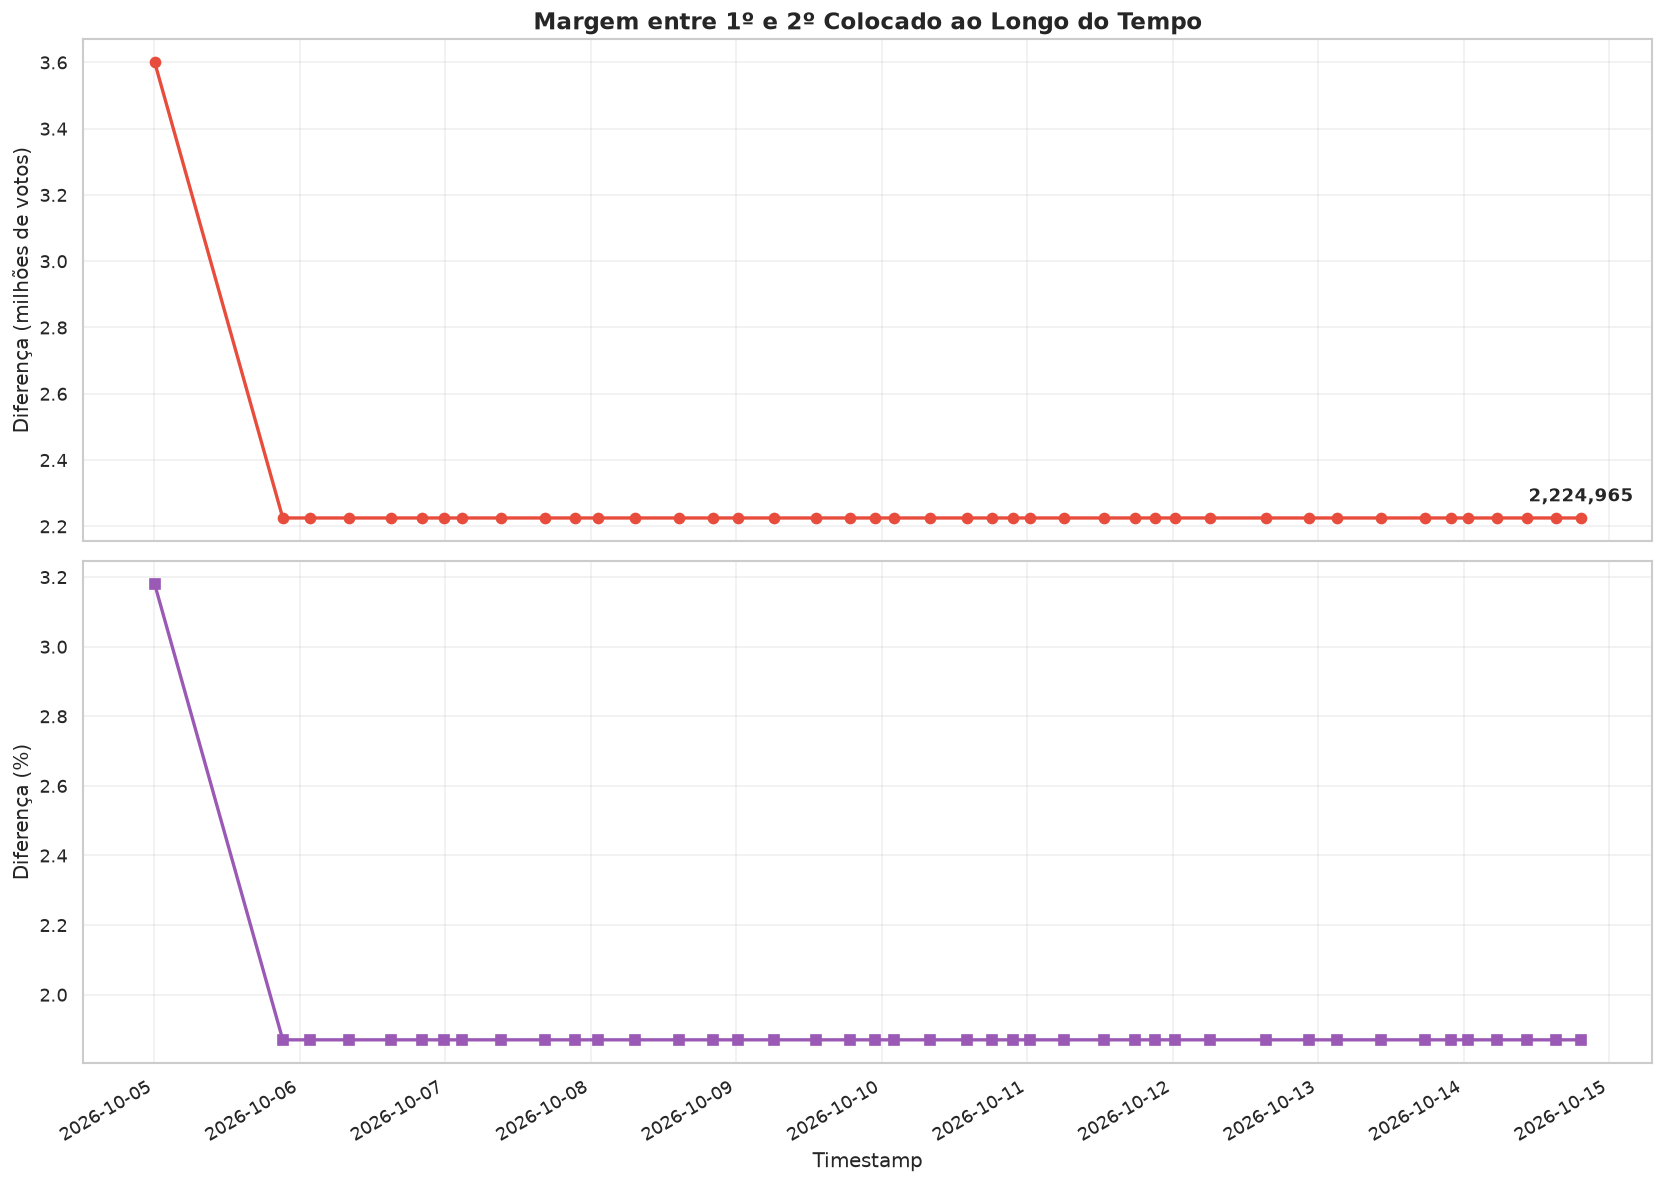

In [7]:

# Calculate margin between top 2 over time
margins = []
for snap in all_snapshots:
    cands = sorted(snap['candidatos'], key=lambda x: x['votos'], reverse=True)
    if len(cands) >= 2:
        top1, top2 = cands[0], cands[1]
        margins.append({
            'timestamp': pd.to_datetime(snap['scraped_at_utc']),
            'lider': top1['nome_urna'],
            'segundo': top2['nome_urna'],
            'votos_lider': top1['votos'],
            'votos_segundo': top2['votos'],
            'diferenca_votos': top1['votos'] - top2['votos'],
            'diferenca_pct': top1['percentual'] - top2['percentual'],
            'pct_apuradas': snap['pct_apuradas']
        })

df_margin = pd.DataFrame(margins).sort_values('timestamp')
print(df_margin.tail())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Votos difference
ax1.plot(df_margin['timestamp'], df_margin['diferenca_votos']/1e6, marker='o', color='#e74c3c', linewidth=2)
ax1.set_ylabel('Diferença (milhões de votos)')
ax1.set_title('Margem entre 1º e 2º Colocado ao Longo do Tempo', fontweight='bold')
ax1.grid(True, alpha=0.3)
for i, row in df_margin.iterrows():
    if row['timestamp'] == df_margin['timestamp'].iloc[-1]:
        ax1.annotate(f"{row['diferenca_votos']:,}", (row['timestamp'], row['diferenca_votos']/1e6),
                     textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

# Percent difference
ax2.plot(df_margin['timestamp'], df_margin['diferenca_pct'], marker='s', color='#9b59b6', linewidth=2)
ax2.set_ylabel('Diferença (%)')
ax2.set_xlabel('Timestamp')
ax2.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('timeseries_margin.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Heatmap de Estabilidade - Últimos Snapshots

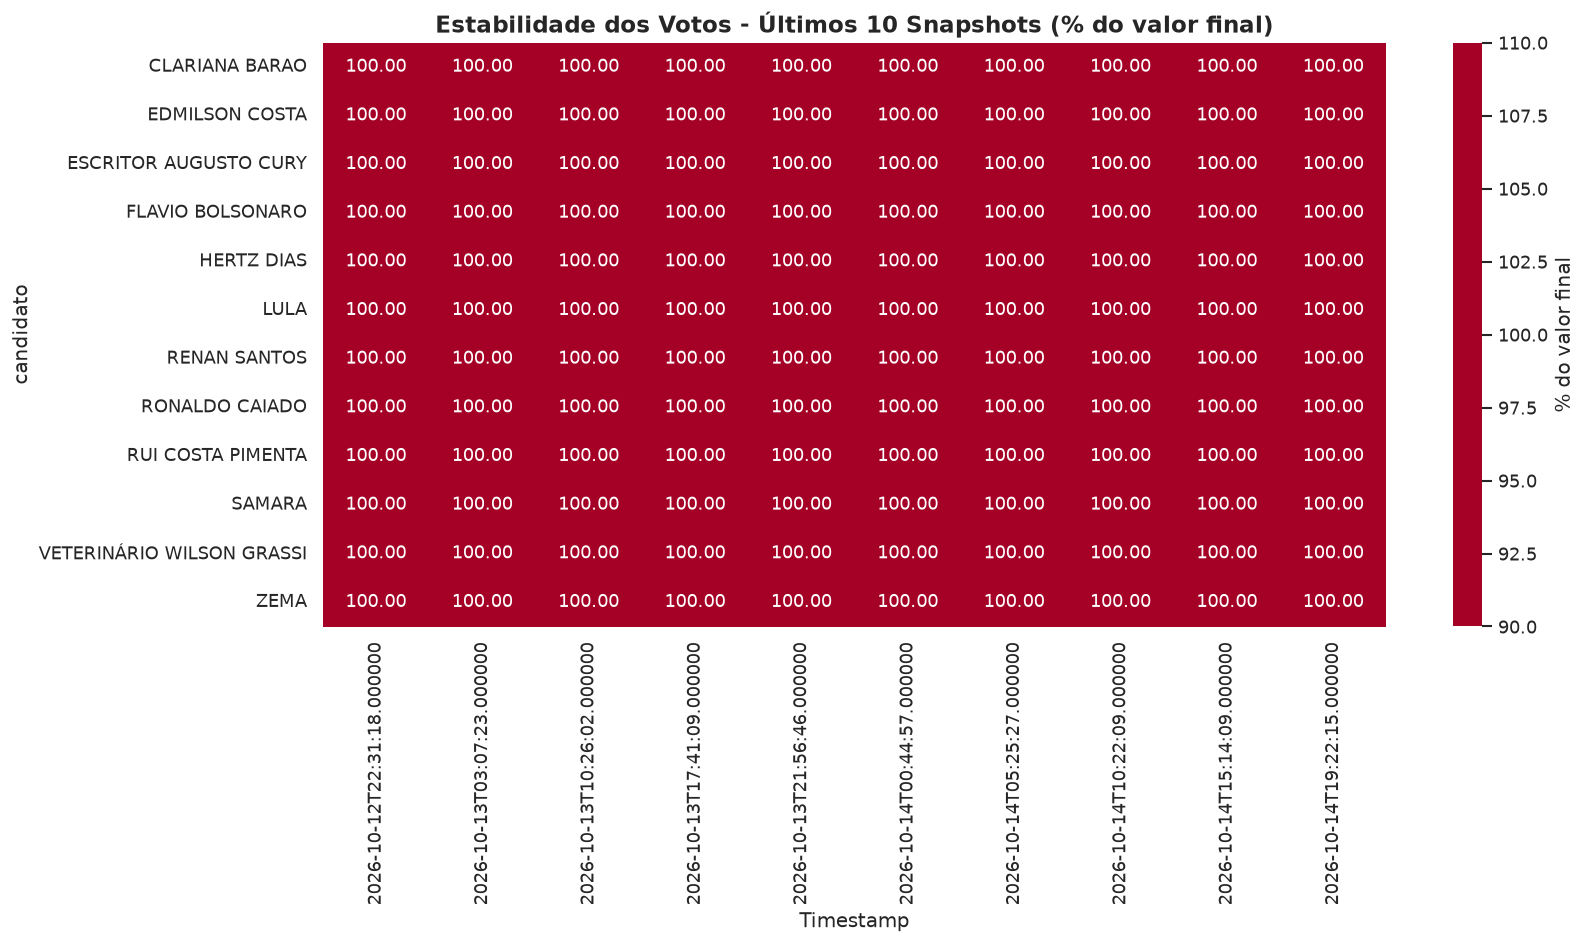

In [8]:

# Show if votes stabilized
df_last = df_pivot_votos.tail(10)
# Normalize to show variation
df_norm = df_last.div(df_last.iloc[-1]) * 100  # % of final value

plt.figure(figsize=(14, 8))
sns.heatmap(df_norm.T, annot=True, fmt='.2f', cmap='RdYlGn', center=100, cbar_kws={'label': '% do valor final'})
plt.title('Estabilidade dos Votos - Últimos 10 Snapshots (% do valor final)', fontweight='bold')
plt.xlabel('Timestamp')
plt.tight_layout()
plt.savefig('timeseries_stability.png', dpi=150, bbox_inches='tight')
plt.show()
